# Figure 6: model selection and calibration

This notebook generates four main figures and one supplementary figure for the frozen 186-participant CN
cohort. It reads completed regional summaries, existing participant-bootstrap comparisons, and
validated ico4 stage summaries. It does **not** refit a normative model or repeat a bootstrap.

All figures use English text. Plotting is summary-based, while the source summaries themselves
were computed from the complete formal OOF predictions.

## 1. Data sources

In [90]:
from pathlib import Path
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "figure6":
    candidate = ROOT / "analysis_results" / "figure6"
    if candidate.is_dir():
        ROOT = candidate
    else:
        raise RuntimeError("Run from the repository root, result root, or notebook directory.")

REGIONAL = ROOT / "regional_warped_m2_186"
ICO4 = ROOT / "ico4_warped_m2_186"
FIGURE_DIR = ROOT / "notebook_figures" / "model_selection_calibration_186"
TABLE_DIR = ROOT / "plotting_inputs" / "model_selection_calibration_186"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

source_paths = {
    "regional_model_bootstrap": REGIONAL / "model_comparison_subject_paired_bootstrap.csv",
    "regional_distribution_summary": REGIONAL / "gaussian_M2_vs_warped_M2.csv",
    "regional_distribution_bootstrap": REGIONAL / "gaussian_vs_warped_subject_paired_bootstrap.csv",
    "regional_gaussian_oof": REGIONAL / "oof_predictions_gaussian_M0_M3_long.parquet",
    "regional_warped_oof": REGIONAL / "oof_predictions_warped_M2_long.parquet",
    "regional_validation": REGIONAL / "unified_model_validation.json",
    "ico4_anchor_validation": ICO4 / "anchor" / "anchor_validation.json",
    "ico4_remaining_validation": ICO4 / "remaining" / "remaining_validation.json",
    "ico4_preflight": ICO4 / "preflight_report.json",
    "ico4_cohort": ICO4 / "frozen_cohort_manifest.csv",
}
missing = [str(path) for path in source_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing required formal result files:\n" + "\n".join(missing))

regional_boot = pd.read_csv(source_paths["regional_model_bootstrap"])
distribution = pd.read_csv(source_paths["regional_distribution_summary"])
distribution_boot = pd.read_csv(source_paths["regional_distribution_bootstrap"])
regional_validation = json.loads(source_paths["regional_validation"].read_text())
anchor = json.loads(source_paths["ico4_anchor_validation"].read_text())
remaining = json.loads(source_paths["ico4_remaining_validation"].read_text())
preflight = json.loads(source_paths["ico4_preflight"].read_text())
cohort = pd.read_csv(source_paths["ico4_cohort"])

pd.DataFrame(
    {"source": source_paths.keys(), "path": [str(p) for p in source_paths.values()]}
)

,source,path
0,regional_model_bootstrap,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
1,regional_distribution_summary,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
2,regional_distribution_bootstrap,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
3,regional_gaussian_oof,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
4,regional_warped_oof,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
5,regional_validation,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
6,ico4_anchor_validation,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
7,ico4_remaining_validation,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
8,ico4_preflight,/mnt/newStor/paros/paros_WORK/xintong/code/cor...
9,ico4_cohort,/mnt/newStor/paros/paros_WORK/xintong/code/cor...


## 2. Metric verification

In [91]:
# Cohort and integrity checks
assert regional_validation["status"] == "complete"
assert regional_validation["cohort_n"] == 186
assert regional_validation["folds"] == 5
assert regional_validation["failed_fits"] == 0
assert anchor["status"] == remaining["status"] == "complete"
assert anchor["failed_fits"] == remaining["failed_fits"] == 0
assert anchor["gaussian_fallbacks"] == remaining["gaussian_fallbacks"] == 0
assert preflight["cohort_n"] == int(cohort["included"].sum()) == 186
assert preflight["n_nodes"] == 4687
assert preflight["n_depths"] == 21

# Figure 1 input: use existing participant-bootstrap estimates and CIs.
contrast_order = ["M1-M0", "M3-M2", "M2-M0"]
contrast_labels = {
    "M1-M0": "M1 − M0: Nonlinear age, without thickness",
    "M3-M2": "M3 − M2: Nonlinear age, with thickness",
    "M2-M0": "M2 − M0: Adding local thickness",
}
fig1_input = (
    regional_boot.query("metric == 'mean_log_loss' and contrast in @contrast_order")
    .set_index("contrast").loc[contrast_order].reset_index()
    .rename(columns={
        "difference_candidate_minus_reference": "delta_mll",
        "ci_low": "ci_lower",
        "ci_high": "ci_upper",
    })
)
fig1_input["comparison_label"] = fig1_input["contrast"].map(contrast_labels)
fig1_input = fig1_input[["contrast", "comparison_label", "delta_mll", "ci_lower", "ci_upper",
                         "n_bootstrap", "seed"]]

# Figure 2A input: observed minus nominal coverage in percentage points.
nominal_map = {"coverage_50": 0.50, "coverage_80": 0.80, "coverage_90": 0.90}
dist21 = distribution.query("scope == 'all_21_depths'").set_index("distribution_model")
coverage_rows = []
for model in ["Gaussian_M2", "warped_M2"]:
    for metric, nominal in nominal_map.items():
        observed = float(dist21.loc[model, metric])
        coverage_rows.append({
            "model": model,
            "display_model": "Gaussian M2" if model == "Gaussian_M2" else "Warped M2",
            "nominal_coverage": nominal,
            "observed_coverage": observed,
            "deviation_percentage_points": 100 * (observed - nominal),
        })
fig2_coverage_input = pd.DataFrame(coverage_rows)

# Figure 2B input: use the existing participant-bootstrap comparison.
fig2_forest_input = (
    distribution_boot.query("metric == 'mean_log_loss'")
    .rename(columns={
        "difference_warped_minus_gaussian": "delta_mll",
        "ci_low": "ci_lower",
        "ci_high": "ci_upper",
    })
    [["contrast", "delta_mll", "ci_lower", "ci_upper", "n_bootstrap", "seed"]]
    .copy()
)
fig2_forest_input["comparison_label"] = "Warped M2 − Gaussian M2"

# Figure 3 input: combine two disjoint formal ico4 stages at full precision.
def pooled_stage_summary(first, second):
    n1 = int(first["calibration"]["n_predictions"])
    n2 = int(second["calibration"]["n_predictions"])
    n = n1 + n2
    c1, c2 = first["calibration"], second["calibration"]
    mean = (n1 * c1["mean_z"] + n2 * c2["mean_z"]) / n
    variance = (
        (n1 - 1) * c1["sd_z"] ** 2
        + (n2 - 1) * c2["sd_z"] ** 2
        + n1 * (c1["mean_z"] - mean) ** 2
        + n2 * (c2["mean_z"] - mean) ** 2
    ) / (n - 1)
    result = {"n_predictions": n, "mean_z": mean, "sd_z": np.sqrt(variance)}
    for metric in ["coverage_50", "coverage_80", "coverage_90"]:
        result[metric] = (n1 * c1[metric] + n2 * c2[metric]) / n
    return result

ico4_summary = pooled_stage_summary(anchor, remaining)
ico4_rows = []
for metric, nominal in nominal_map.items():
    observed = ico4_summary[metric]
    ico4_rows.append({
        "nominal_coverage": nominal,
        "observed_coverage": observed,
        "deviation_percentage_points": 100 * (observed - nominal),
        "mean_z": ico4_summary["mean_z"],
        "sd_z": ico4_summary["sd_z"],
        "n_predictions": ico4_summary["n_predictions"],
        "n_participants": preflight["cohort_n"],
        "n_nodes": preflight["n_nodes"],
        "n_depths": preflight["n_depths"],
    })
fig3_input = pd.DataFrame(ico4_rows)

# Audit against the values supplied for plotting. Values are compared at their stated precision.
expected_fig1 = {
    "M1-M0": (0.000390, -0.008315, 0.009655),
    "M3-M2": (-0.001967, -0.010866, 0.007417),
    "M2-M0": (-0.015627, -0.021215, -0.010069),
}
expected_fig2 = {
    ("Gaussian M2", 0.50): 3.41, ("Warped M2", 0.50): 0.44,
    ("Gaussian M2", 0.80): 2.25, ("Warped M2", 0.80): 0.51,
    ("Gaussian M2", 0.90): 0.91, ("Warped M2", 0.90): 0.42,
}
expected_fig2_forest = (-0.022927, -0.034351, -0.012741)
expected_fig3 = {0.50: -0.23, 0.80: 0.30, 0.90: 0.38}

audit_rows = []
for row in fig1_input.itertuples():
    for field, observed, expected in zip(
        ["delta_mll", "ci_lower", "ci_upper"],
        [row.delta_mll, row.ci_lower, row.ci_upper], expected_fig1[row.contrast]
    ):
        audit_rows.append({"figure": "Figure 1", "item": f"{row.contrast} {field}",
                           "formal_value": observed, "provided_value": expected,
                           "display_decimals": 6,
                           "matches_at_display_precision": round(observed, 6) == round(expected, 6)})
for row in fig2_coverage_input.itertuples():
    expected = expected_fig2[(row.display_model, row.nominal_coverage)]
    audit_rows.append({"figure": "Figure 2A",
                       "item": f"{row.display_model}, {row.nominal_coverage:.0%}",
                       "formal_value": row.deviation_percentage_points, "provided_value": expected,
                       "display_decimals": 2,
                       "matches_at_display_precision": round(row.deviation_percentage_points, 2) == expected})
forest_row = fig2_forest_input.iloc[0]
for field, expected in zip(["delta_mll", "ci_lower", "ci_upper"], expected_fig2_forest):
    observed = float(forest_row[field])
    audit_rows.append({"figure": "Figure 2B", "item": field, "formal_value": observed,
                       "provided_value": expected, "display_decimals": 6,
                       "matches_at_display_precision": round(observed, 6) == round(expected, 6)})
for row in fig3_input.itertuples():
    expected = expected_fig3[row.nominal_coverage]
    audit_rows.append({"figure": "Figure 3", "item": f"{row.nominal_coverage:.0%}",
                       "formal_value": row.deviation_percentage_points, "provided_value": expected,
                       "display_decimals": 2,
                       "matches_at_display_precision": round(row.deviation_percentage_points, 2) == expected})
audit = pd.DataFrame(audit_rows)
display(audit)
if not audit["matches_at_display_precision"].all():
    raise RuntimeError("Formal result values differ from the supplied values at display precision.")

print("All supplied values match the formal files at the requested display precision.")
print("No model was refit and no bootstrap was repeated.")

,figure,item,formal_value,provided_value,display_decimals,matches_at_display_precision
0,Figure 1,M1-M0 delta_mll,0.000390,0.000390,6,True
1,Figure 1,M1-M0 ci_lower,-0.008315,-0.008315,6,True
2,Figure 1,M1-M0 ci_upper,0.009655,0.009655,6,True
3,Figure 1,M3-M2 delta_mll,-0.001967,-0.001967,6,True
4,Figure 1,M3-M2 ci_lower,-0.010866,-0.010866,6,True
5,Figure 1,M3-M2 ci_upper,0.007417,0.007417,6,True
6,Figure 1,M2-M0 delta_mll,-0.015627,-0.015627,6,True
7,Figure 1,M2-M0 ci_lower,-0.021215,-0.021215,6,True
8,Figure 1,M2-M0 ci_upper,-0.010069,-0.010069,6,True
9,Figure 2A,"Gaussian M2, 50%",3.409159,3.410000,2,True


All supplied values match the formal files at the requested display precision.
No model was refit and no bootstrap was repeated.


In [92]:
# Retain the exact plotting inputs and the value audit.
fig1_input.to_csv(TABLE_DIR / "figure1_regional_model_selection.csv", index=False)
fig2_coverage_input.to_csv(TABLE_DIR / "figure2a_regional_coverage_deviation.csv", index=False)
fig2_forest_input.to_csv(TABLE_DIR / "figure2b_warped_vs_gaussian_mll.csv", index=False)
fig3_input.to_csv(TABLE_DIR / "figure3_ico4_calibration.csv", index=False)
audit.to_csv(TABLE_DIR / "provided_value_audit.csv", index=False)

display(fig1_input)
display(fig2_coverage_input)
display(fig2_forest_input)
display(fig3_input)

,contrast,comparison_label,delta_mll,ci_lower,ci_upper,n_bootstrap,seed
0,M1-M0,"M1 − M0: Nonlinear age, without thickness",0.000390,-0.008315,0.009655,10000,20261108
1,M3-M2,"M3 − M2: Nonlinear age, with thickness",-0.001967,-0.010866,0.007417,10000,20261108
2,M2-M0,M2 − M0: Adding local thickness,-0.015627,-0.021215,-0.010069,10000,20261108


,model,display_model,nominal_coverage,observed_coverage,deviation_percentage_points
0,Gaussian_M2,Gaussian M2,0.5,0.534092,3.409159
1,Gaussian_M2,Gaussian M2,0.8,0.822468,2.246770
2,Gaussian_M2,Gaussian M2,0.9,0.909095,0.909536
3,warped_M2,Warped M2,0.5,0.504352,0.435228
4,warped_M2,Warped M2,0.8,0.805119,0.511882
5,warped_M2,Warped M2,0.9,0.904235,0.423481


,contrast,delta_mll,ci_lower,ci_upper,n_bootstrap,seed,comparison_label
0,warped_M2-Gaussian_M2,-0.022927,-0.034351,-0.012741,10000,20261110,Warped M2 − Gaussian M2


,nominal_coverage,observed_coverage,deviation_percentage_points,mean_z,sd_z,n_predictions,n_participants,n_nodes,n_depths
0,0.5,0.497707,-0.229283,-0.0205,1.00368,18100551,186,4687,21
1,0.8,0.802967,0.296749,-0.0205,1.00368,18100551,186,4687,21
2,0.9,0.903809,0.380901,-0.0205,1.00368,18100551,186,4687,21


## 3. Plotting

In [93]:
# Shared publication style. The full palette and plotting code live in this notebook
# so colors, marker sizes, and line widths can be adjusted here directly.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.grid": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLORS = {
    "blue": "#4B74B2",
    "light_blue": "#90BEE0",
    "orange": "#FC8C5A",
    "red": "#DB3124",
    "yellow": "#FFDF92",
    "gray": "#8A8A8A",
    "dark_gray": "#333333",
    "zero": "#8A8A8A",
}

POINT_SIZE = 9
POINT_EDGE_WIDTH = 2.0
ERROR_LINE_WIDTH = 1.6
ERROR_CAP_SIZE = 3
ERROR_CAP_THICKNESS = 1.2

def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out")

def export_figure(fig, stem):
    paths = []
    for suffix, kwargs in [("png", {"dpi": 300}), ("pdf", {}), ("svg", {})]:
        path = FIGURE_DIR / f"{stem}.{suffix}"
        fig.savefig(path, bbox_inches="tight", **kwargs)
        paths.append(path)
    return paths

exported = []

### Figure 1. Regional model selection

findfont: Failed to find font weight semibold, now using 700.


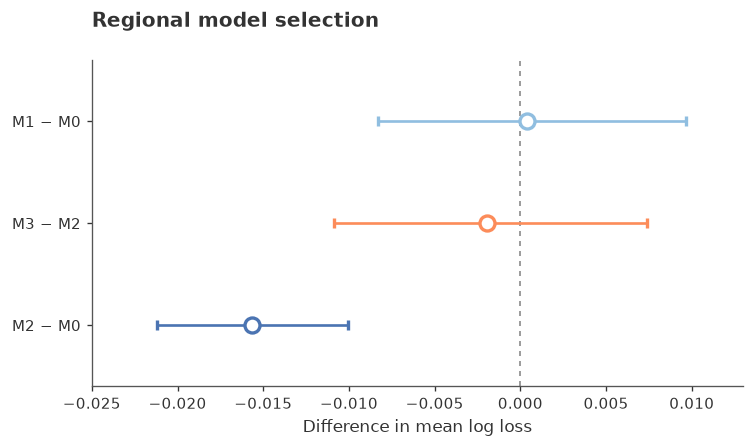

In [94]:
plot = fig1_input.copy()
y = np.arange(len(plot))[::-1]
colors = [COLORS["light_blue"], COLORS["orange"], COLORS["blue"]]

fig, ax = plt.subplots(figsize=(9.2, 4.25))
for yi, row, color in zip(y, plot.itertuples(), colors):
    ax.errorbar(
        row.delta_mll, yi,
        xerr=[[row.delta_mll - row.ci_lower], [row.ci_upper - row.delta_mll]],
        fmt="o", ms=POINT_SIZE, color=color, ecolor=color,
        markerfacecolor="white", markeredgecolor=color,
        markeredgewidth=POINT_EDGE_WIDTH, elinewidth=ERROR_LINE_WIDTH,
        capsize=ERROR_CAP_SIZE, capthick=ERROR_CAP_THICKNESS, zorder=3,
    )
ax.axvline(0, color=COLORS["zero"], linestyle=(0, (3, 3)), linewidth=1)
short_comparison_labels = plot["contrast"].str.replace("-", " − ", regex=False)
ax.set_yticks(y, short_comparison_labels)
ax.set_xlabel("Difference in mean log loss")
ax.set_title("Regional model selection", loc="left", fontweight="semibold", pad=20)
ax.set_xlim(-0.025, 0.013)
ax.set_ylim(-0.6, len(plot) - 0.4)
clean_axis(ax)
fig.subplots_adjust(left=0.39, bottom=0.18, right=0.98, top=0.82)
exported.extend(export_figure(fig, "figure1_regional_delta_mll_forest"))
plt.show()

**Caption.** Regional model-selection contrasts in mean log loss (−logp; lower is better). Points are paired differences and horizontal intervals are 95% confidence intervals from participant-level bootstrap resampling.

### Figure 2. Regional Gaussian versus Warped

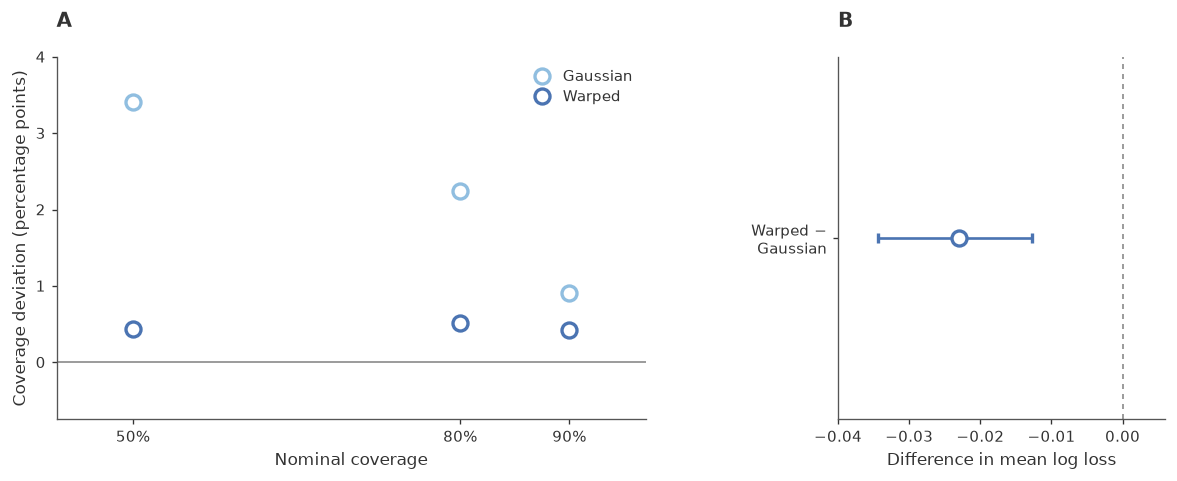

In [95]:
fig, (ax_a, ax_b) = plt.subplots(
    1, 2, figsize=(10.5, 4.65), gridspec_kw={"width_ratios": [1.8, 1.0], "wspace": 0.42}
)

offsets = {"Gaussian M2": 0.0, "Warped M2": 0.0}
model_colors = {"Gaussian M2": COLORS["light_blue"], "Warped M2": COLORS["blue"]}
for model in ["Gaussian M2", "Warped M2"]:
    d = fig2_coverage_input.query("display_model == @model")
    x = 100 * d["nominal_coverage"].to_numpy() + offsets[model]
    ax_a.plot(x, d["deviation_percentage_points"], linestyle="none", marker="o",
              ms=POINT_SIZE, markerfacecolor="white",
              markeredgecolor=model_colors[model], markeredgewidth=POINT_EDGE_WIDTH,
              color=model_colors[model], label=model.replace(" M2", ""))
ax_a.axhline(0, color=COLORS["zero"], linewidth=1)
ax_a.set_xticks([50, 80, 90], ["50%", "80%", "90%"])
ax_a.set_xlim(43, 97)
ax_a.set_ylim(-0.75, 4.0)
ax_a.set_xlabel("Nominal coverage")
ax_a.set_ylabel("Coverage deviation (percentage points)")
ax_a.legend(frameon=False, loc="upper right")
ax_a.set_title("A", loc="left", fontweight="bold", pad=18)
clean_axis(ax_a)

row = fig2_forest_input.iloc[0]
ax_b.errorbar(
    row.delta_mll, 0,
    xerr=[[row.delta_mll - row.ci_lower], [row.ci_upper - row.delta_mll]],
    fmt="o", ms=POINT_SIZE, color=COLORS["blue"], ecolor=COLORS["blue"],
    markerfacecolor="white", markeredgecolor=COLORS["blue"],
    markeredgewidth=POINT_EDGE_WIDTH, elinewidth=ERROR_LINE_WIDTH,
    capsize=ERROR_CAP_SIZE, capthick=ERROR_CAP_THICKNESS,
)
ax_b.axvline(0, color=COLORS["zero"], linestyle=(0, (3, 3)), linewidth=1)
ax_b.set_yticks([0], ["Warped −\nGaussian"])
ax_b.set_ylim(-0.75, 0.75)
ax_b.set_xlim(-0.040, 0.006)
ax_b.set_xlabel("Difference in mean log loss")
ax_b.set_title("B", loc="left", fontweight="bold", pad=18)
clean_axis(ax_b)

fig.subplots_adjust(left=0.10, bottom=0.18, right=0.98, top=0.83)
exported.extend(export_figure(fig, "figure2_regional_gaussian_vs_warped"))
plt.show()

**Caption.** Regional Gaussian and Warped M2 calibration. Panel A reports observed-minus-nominal coverage without uncertainty intervals because no corresponding participant-bootstrap intervals were available. Panel B reports the mean-log-loss difference and its participant-bootstrap 95% confidence interval.

### Figure 3. Regional OOF z-score distributions

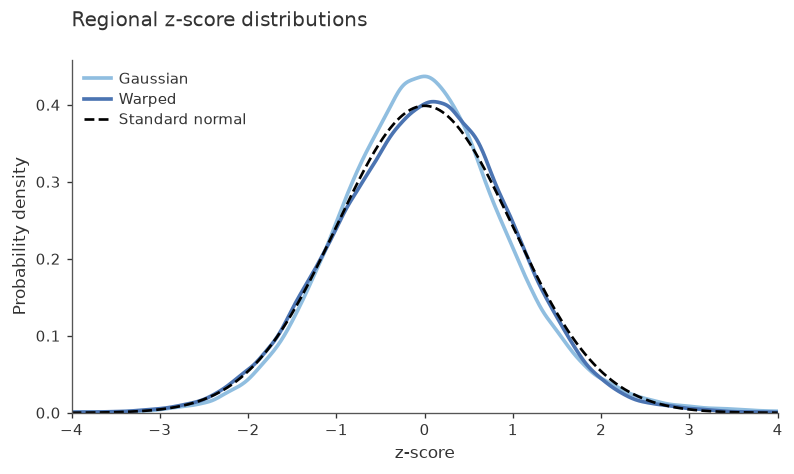

,Gaussian,Warped
Skewness,0.427,-0.001
Excess kurtosis,2.506,0.835
Fraction |z| > 3,0.825,0.524


In [96]:
# Frozen 186-participant regional OOF predictions; no model is refitted.
regional_keys = ["subject_id", "outer_fold", "region_index", "hemisphere",
                 "dk_label_id", "depth_index"]
gaussian_oof = pd.read_parquet(
    source_paths["regional_gaussian_oof"],
    columns=regional_keys + ["model", "observed_md", "z"],
).query("model == 'M2'").drop(columns="model")
warped_oof = pd.read_parquet(
    source_paths["regional_warped_oof"],
    columns=regional_keys + ["observed_md", "z"],
)
regional_matched = gaussian_oof.merge(
    warped_oof, on=regional_keys, how="inner", validate="one_to_one",
    suffixes=("_gaussian", "_warped"),
)
assert len(regional_matched) == len(gaussian_oof) == len(warped_oof) == 265_608
assert regional_matched["subject_id"].nunique() == 186
assert regional_matched["region_index"].nunique() == 68
assert regional_matched["depth_index"].nunique() == 21
assert np.allclose(regional_matched["observed_md_gaussian"],
                   regional_matched["observed_md_warped"], rtol=0, atol=1e-12)

z_gaussian = regional_matched["z_gaussian"].to_numpy(float)
z_warped = regional_matched["z_warped"].to_numpy(float)
assert np.isfinite(z_gaussian).all() and np.isfinite(z_warped).all()

def regional_z_statistics(z):
    return {
        "Skewness": stats.skew(z, bias=True),
        "Excess kurtosis": stats.kurtosis(z, fisher=True, bias=True),
        "Fraction |z| > 3": np.mean(np.abs(z) > 3),
    }

regional_z_stats = pd.DataFrame({
    "Gaussian": regional_z_statistics(z_gaussian),
    "Warped": regional_z_statistics(z_warped),
})
assert np.allclose(regional_z_stats.loc["Skewness"], [0.427, -0.001], atol=5e-4)
assert np.allclose(regional_z_stats.loc["Excess kurtosis"], [2.506, 0.835], atol=5e-4)
assert np.allclose(regional_z_stats.loc["Fraction |z| > 3"], [0.00825, 0.00524], atol=5e-6)
regional_z_stats.to_csv(TABLE_DIR / "figure3_regional_z_statistics.csv")

# Identical Gaussian KDE method and Scott bandwidth rule; all matched values are used.
density_grid = np.linspace(-4, 4, 801)
gaussian_density = stats.gaussian_kde(z_gaussian, bw_method="scott")(density_grid)
warped_density = stats.gaussian_kde(z_warped, bw_method="scott")(density_grid)
normal_density = stats.norm.pdf(density_grid)

fig, ax = plt.subplots(figsize=(7.09, 4.6))
ax.plot(density_grid, gaussian_density, color=COLORS["light_blue"], linewidth=2.2, label="Gaussian")
ax.plot(density_grid, warped_density, color=COLORS["blue"], linewidth=2.2, label="Warped")
ax.plot(density_grid, normal_density, color="black", linewidth=1.6, linestyle="--", label="Standard normal")
ax.set_xlim(-4, 4)
ax.set_ylim(bottom=0)
ax.set_xlabel("z-score")
ax.set_ylabel("Probability density")
ax.set_title("Regional z-score distributions", loc="left", pad=20)
ax.legend(frameon=False, loc="upper left")
clean_axis(ax)
fig.subplots_adjust(left=0.14, right=0.97, bottom=0.16, top=0.80)
exported.extend(export_figure(fig, "figure3_regional_gaussian_vs_warped_oof_z_distribution"))
plt.show()

stats_display = regional_z_stats.copy()
stats_display.loc["Fraction |z| > 3"] *= 100
display(stats_display.style.format("{:.3f}").set_properties(**{"text-align": "right"}))

**Caption.** Gaussian M2 and Warped M2 densities use all 265,608 matched valid OOF observations and the same Gaussian KDE with Scott's bandwidth rule. The black dashed curve is $N(0,1)$. Only the displayed x-axis is limited to $[-4,4]$; density estimation and statistics use the complete distributions. The last table row is reported as percent. No observation-level significance test is performed.

### Figure 4. Overall ico4 calibration

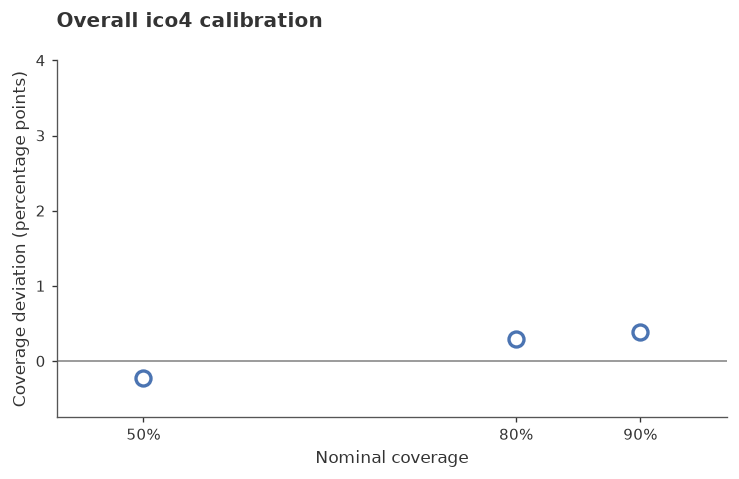

In [97]:
fig, ax = plt.subplots(figsize=(6.9, 4.65))
x = 100 * fig3_input["nominal_coverage"].to_numpy()
y = fig3_input["deviation_percentage_points"].to_numpy()
ax.plot(x, y, linestyle="none", marker="o", ms=POINT_SIZE,
        markerfacecolor="white", markeredgecolor=COLORS["blue"],
        markeredgewidth=POINT_EDGE_WIDTH, color=COLORS["blue"])
ax.axhline(0, color=COLORS["zero"], linewidth=1)
ax.set_xticks([50, 80, 90], ["50%", "80%", "90%"])
ax.set_xlim(43, 97)
ax.set_ylim(-0.75, 4.0)
ax.set_xlabel("Nominal coverage")
ax.set_ylabel("Coverage deviation (percentage points)")
ax.set_title("Overall ico4 calibration", loc="left", fontweight="semibold", pad=20)
clean_axis(ax)
fig.subplots_adjust(left=0.16, bottom=0.18, right=0.97, top=0.82)
exported.extend(export_figure(fig, "figure4_ico4_overall_calibration"))
plt.show()

**Caption.** Overall ico4 Warped-M2 OOF calibration across 186 participants, 4,687 bilateral nodes and 21 depths. Points show observed-minus-nominal coverage. No uncertainty intervals are shown because a combined participant-bootstrap analysis has not yet been performed.

### Supplementary figure. Gompertz pilot performance and fit stability

This supplement places the paired predictive comparison beside the diagnostics that prevented
promotion of Gompertz. The baseline Warped linear OOF predictions are reused; this section does
not refit either model, repeat the bootstrap, or run ico4. The three plotted diagnostic categories
are nonexclusive. A near-zero age coefficient is retained only in the accompanying audit table;
it is not classified as a fitting failure because it may reflect a genuine weak age effect.

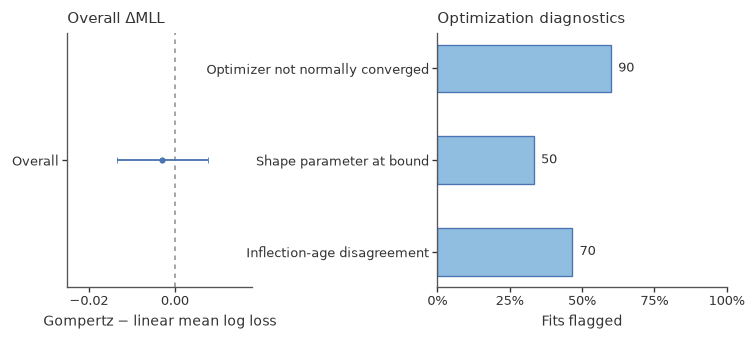

,scope,depth_index,display_label,delta_mll,ci_low,ci_high,probability_candidate_better,n_subjects,n_observations,observations_per_subject,n_bootstrap,seed
22,overall,all,Overall,-0.003007,-0.013546,0.007722,0.7177,186,5580,30,10000,20261111


,scope,depth_index,display_label,delta_mll,ci_low,ci_high,probability_candidate_better,n_subjects,n_observations,observations_per_subject,n_bootstrap,seed
23,by_depth,0,Depth 0.00,-0.001179,-0.016161,0.014026,0.5599,186,1116,6,10000,20261111
24,by_depth,4,Depth 0.20,-0.006407,-0.021603,0.008909,0.7940,186,1116,6,10000,20261111
25,by_depth,10,Depth 0.50,-0.004700,-0.016543,0.007048,0.7845,186,1116,6,10000,20261111
26,by_depth,16,Depth 0.80,-0.002213,-0.014717,0.011876,0.6385,186,1116,6,10000,20261111
27,by_depth,20,Depth 1.00,-0.000537,-0.012057,0.012343,0.5544,186,1116,6,10000,20261111


,diagnostic,source_field,n_flagged,n_fits,percent_flagged,included_in_figure,interpretation
0,Optimizer not normally converged,outer_optimizer_failures,90,150,60.000000,True,Optimization convergence diagnostic
1,Shape parameter at bound,shape_at_bound,50,150,33.333333,True,Boundary diagnostic
2,Inflection-age disagreement,large_multistart_inflection_disagreement,70,150,46.666667,True,Multistart solutions differ by more than 5 years
3,Near-zero age effect,near_zero_age_effect,38,150,25.333333,False,Retained for audit only; not interpreted as a ...


Saved: /mnt/newStor/paros/paros_WORK/xintong/result/cortical_trajectory_analysis/analysis_results/figure6/notebook_figures/model_selection_calibration_186/figureS_gompertz_pilot_performance_stability
No model was refit, no bootstrap was repeated, and ico4 was not run.


In [98]:
import sys

AGE_FUNCTION = ROOT / "regional_age_function_comparison_186" / "comparison"
gompertz_sources = {
    "paired_bootstrap": AGE_FUNCTION / "paired_subject_bootstrap_delta_mll.csv",
    "fit_stability": AGE_FUNCTION / "fit_stability_summary.csv",
    "model_decision": AGE_FUNCTION / "model_decision.json",
}
missing = [str(path) for path in gompertz_sources.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing formal Gompertz comparison files:\n" + "\n".join(missing))

gompertz_bootstrap = pd.read_csv(gompertz_sources["paired_bootstrap"])
gompertz_bootstrap = gompertz_bootstrap.query("candidate == 'warped_gompertz'").copy()
gompertz_stability = pd.read_csv(gompertz_sources["fit_stability"])
gompertz_stability = gompertz_stability.query("model == 'warped_gompertz'").iloc[0]
gompertz_decision = json.loads(gompertz_sources["model_decision"].read_text())["warped_gompertz"]

# The pilot is exactly paired on 186 participants, six prespecified regions, and five depths.
overall = gompertz_bootstrap.query("scope == 'overall'").iloc[0]
by_depth = gompertz_bootstrap.query("scope == 'by_depth'").copy()
by_depth["depth_index"] = by_depth["depth_index"].astype(int)
assert len(gompertz_bootstrap) == 6
assert by_depth["depth_index"].tolist() == [0, 4, 10, 16, 20]
assert int(overall["n_subjects"]) == 186
assert int(overall["n_observations"]) == 5_580
assert int(overall["observations_per_subject"]) == 30
assert int(overall["n_bootstrap"]) == 10_000
assert int(gompertz_stability["fits_successful"]) == 150
assert int(gompertz_stability["task_failures"]) == 0
np.testing.assert_allclose(
    [overall["delta_mll"], overall["ci_low"], overall["ci_high"]],
    [gompertz_decision["delta_mll_pilot"], *gompertz_decision["ci_95"]],
    rtol=0, atol=1e-12,
)

overall_input = pd.DataFrame([overall])
overall_input["display_label"] = "Overall"
overall_input = overall_input[[
    "scope", "depth_index", "display_label", "delta_mll", "ci_low", "ci_high",
    "probability_candidate_better", "n_subjects", "n_observations",
    "observations_per_subject", "n_bootstrap", "seed",
]]
depth_input = by_depth.copy()
depth_input["display_label"] = [
    f"Depth {index / 20:.2f}" for index in depth_input["depth_index"]
]
depth_input = depth_input[[
    "scope", "depth_index", "display_label", "delta_mll", "ci_low", "ci_high",
    "probability_candidate_better", "n_subjects", "n_observations",
    "observations_per_subject", "n_bootstrap", "seed",
]]

diagnostic_specs = [
    ("Optimizer not normally converged", "outer_optimizer_failures", True,
     "Optimization convergence diagnostic"),
    ("Shape parameter at bound", "shape_at_bound", True,
     "Boundary diagnostic"),
    ("Inflection-age disagreement", "large_multistart_inflection_disagreement", True,
     "Multistart solutions differ by more than 5 years"),
    ("Near-zero age effect", "near_zero_age_effect", False,
     "Retained for audit only; not interpreted as a fitting failure"),
]
fit_total = int(gompertz_stability["fits_successful"])
diagnostic_input = pd.DataFrame([
    {
        "diagnostic": label,
        "source_field": field,
        "n_flagged": int(gompertz_stability[field]),
        "n_fits": fit_total,
        "percent_flagged": 100 * float(gompertz_stability[field]) / fit_total,
        "included_in_figure": include_in_figure,
        "interpretation": interpretation,
    }
    for label, field, include_in_figure, interpretation in diagnostic_specs
])
for row in diagnostic_input.itertuples():
    assert row.n_flagged == int(gompertz_decision[row.source_field])
plotted_diagnostics = diagnostic_input.query("included_in_figure").copy()
assert len(plotted_diagnostics) == 3

overall_input.to_csv(TABLE_DIR / "figureS_gompertz_delta_mll.csv", index=False)
depth_input.to_csv(TABLE_DIR / "figureS_gompertz_depth_delta_mll_supplement.csv", index=False)
diagnostic_input.to_csv(TABLE_DIR / "figureS_gompertz_fit_stability.csv", index=False)

# Use the paper-wide semantic palette, typography, no-grid rule, and export settings.
PROJECT_ROOT = ROOT.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from qc.publication_style import (  # noqa: E402
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure, set_publication_style,
)

set_publication_style()
fig, (ax_effect, ax_stability) = plt.subplots(
    1, 2,
    figsize=(FIGURE_WIDTH_IN, 2.75),
    gridspec_kw={"width_ratios": [0.78, 1.22], "wspace": 0.78},
)

# Overall participant-bootstrap contrast; depth-specific results remain in a separate table.
overall_row = overall_input.iloc[0]
ax_effect.errorbar(
    overall_row["delta_mll"], 0,
    xerr=[
        [overall_row["delta_mll"] - overall_row["ci_low"]],
        [overall_row["ci_high"] - overall_row["delta_mll"]],
    ],
    fmt="o", markersize=3.8, markerfacecolor=PALETTE["blue"],
    markeredgecolor=PALETTE["blue"], markeredgewidth=0.8,
    color=PALETTE["blue"], ecolor=PALETTE["blue"],
    elinewidth=1.1, capsize=2.2, capthick=0.8, zorder=3,
)
ax_effect.axvline(0, color=PALETTE["gray"], linestyle=(0, (3, 3)), linewidth=0.9)
ax_effect.set_yticks([0], ["Overall"])
ax_effect.set_xlim(-0.025, 0.018)
ax_effect.set_ylim(-0.65, 0.65)
ax_effect.set_xlabel("Gompertz − linear mean log loss")
ax_effect.set_title("Overall ΔMLL", loc="left")

# These flags can overlap, so percentages are shown against the same 150-fit denominator.
bar_y = np.arange(len(plotted_diagnostics))[::-1]
bars = ax_stability.barh(
    bar_y, plotted_diagnostics["percent_flagged"], height=0.52,
    color=PALETTE["light_blue"], edgecolor=PALETTE["blue"], linewidth=0.8,
)
ax_stability.set_yticks(bar_y, plotted_diagnostics["diagnostic"])
ax_stability.set_xlim(0, 100)
ax_stability.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax_stability.set_xlabel("Fits flagged")
ax_stability.set_title("Optimization diagnostics", loc="left")
for bar, row in zip(bars, plotted_diagnostics.itertuples()):
    ax_stability.text(
        min(row.percent_flagged + 2.5, 93), bar.get_y() + bar.get_height() / 2,
        f"{row.n_flagged}", ha="left", va="center", fontsize=7.5,
    )

figure_stem = FIGURE_DIR / "figureS_gompertz_pilot_performance_stability"
save_publication_figure(fig, figure_stem)
plt.show()

display(overall_input)
display(depth_input)
display(diagnostic_input)
print("Saved:", figure_stem)
print("No model was refit, no bootstrap was repeated, and ico4 was not run.")

**Caption.** Warped Gompertz pilot compared with the reused Warped linear OOF predictions for the same 186 participants, six DK regions, and five normalized depths (5,580 observations). The left panel shows the overall candidate-minus-linear mean-log-loss difference and its 95% confidence interval from 10,000 participant-level bootstrap resamples; negative values favor Gompertz. The right panel shows three nonexclusive optimization and identifiability flags among 150 region-by-depth-by-outer-fold fits: 90 outer optimizations did not report normal convergence, 50 fits ended at a shape bound, and 70 had greater than 5-year disagreement among multistart inflection-age solutions. All predictions were finite and no paired observation was excluded. The overall interval included zero and the pilot was not promoted. Depth-specific comparisons are reported separately in the supplementary table.

## 4. Export

In [99]:
captions = pd.DataFrame([
    {
        "figure": "Figure 1",
        "caption": "Regional model-selection contrasts in mean log loss (−logp; lower is better). "
                   "Points are paired differences and horizontal intervals are 95% confidence "
                   "intervals from participant-level bootstrap resampling."
    },
    {
        "figure": "Figure 2",
        "caption": "Regional Gaussian and Warped M2 calibration. Panel A reports coverage deviation; "
                   "Panel B reports the mean-log-loss contrast with its participant-bootstrap 95% CI."
    },
    {
        "figure": "Figure 3",
        "caption": "Regional Gaussian M2 and Warped M2 OOF z-score densities on the exact same "
                   "265,608 valid observations, with a standard-normal reference. Only the displayed "
                   "x-axis is restricted to −4 to 4."
    },
    {
        "figure": "Figure 4",
        "caption": "Overall ico4 Warped-M2 OOF calibration across 186 participants, 4,687 bilateral "
                   "nodes and 21 depths. No participant-bootstrap intervals are shown."
    },
])
captions = pd.concat([captions, pd.DataFrame([{
    "figure": "Supplementary Figure",
    "caption": 'Warped Gompertz pilot compared with the reused Warped linear OOF predictions for the same 186 participants, six DK regions, and five normalized depths (5,580 observations). The left panel shows the overall candidate-minus-linear mean-log-loss difference and its 95% confidence interval from 10,000 participant-level bootstrap resamples; negative values favor Gompertz. The right panel shows three nonexclusive optimization and identifiability flags among 150 region-by-depth-by-outer-fold fits: 90 outer optimizations did not report normal convergence, 50 fits ended at a shape bound, and 70 had greater than 5-year disagreement among multistart inflection-age solutions. All predictions were finite and no paired observation was excluded. The overall interval included zero and the pilot was not promoted. Depth-specific comparisons are reported separately in the supplementary table.',
}])], ignore_index=True)

captions.to_csv(TABLE_DIR / "figure_captions.csv", index=False)

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

all_outputs = sorted(FIGURE_DIR.glob("figure*.*")) + sorted(TABLE_DIR.glob("*.csv"))
manifest = pd.DataFrame([
    {"path": str(path.relative_to(ROOT)), "bytes": path.stat().st_size, "sha256": sha256(path)}
    for path in all_outputs
])
manifest.to_csv(TABLE_DIR / "export_manifest.csv", index=False)
display(manifest)

print(f"Exported {len(list(FIGURE_DIR.glob('*.png')))} PNG files, "
      f"{len(list(FIGURE_DIR.glob('*.pdf')))} PDF files, and "
      f"{len(list(FIGURE_DIR.glob('*.svg')))} SVG files.")
print(f"Figure directory: {FIGURE_DIR}")
print(f"Plotting-input directory: {TABLE_DIR}")

,path,bytes,sha256
0,notebook_figures/model_selection_calibration_1...,57899,e4603d7da16afb2f281186e8989a611792f12c0ca4d142...
1,notebook_figures/model_selection_calibration_1...,57824,099b6a7ee2addbfc354bf7fbeaa004b26fa47bde5cf0e3...
2,notebook_figures/model_selection_calibration_1...,11774,06ba5a77e7f4cca8fb7c5144f7b586e3b5b92a3b38c14a...
3,notebook_figures/model_selection_calibration_1...,60563,00d996806b11bef7796d4e7ddf4b6ebeca72650a1b82e2...
4,notebook_figures/model_selection_calibration_1...,112569,ffb516d49cc41ff4b5f7b4bb433c4ef5374db116a27f2d...
5,notebook_figures/model_selection_calibration_1...,14151,c4977776f04efbdea2852825e14f77f355066a43ca3dbf...
6,notebook_figures/model_selection_calibration_1...,33383,56da0937d14f6c6b6c1dfdae7fe7aa4cfc72f2dd32a285...
7,notebook_figures/model_selection_calibration_1...,67848,ec289e8924516fc08900df83435aa78f2df9dc4c7602f1...
8,notebook_figures/model_selection_calibration_1...,30991,99ed3b812daa90d5e2bc9fa8366cff759762f4a856e61a...
9,notebook_figures/model_selection_calibration_1...,29430,faae10d2a504f8f78e85d92dc6f4252ab278cf48c97e4f...


Exported 6 PNG files, 6 PDF files, and 6 SVG files.
Figure directory: /mnt/newStor/paros/paros_WORK/xintong/result/cortical_trajectory_analysis/analysis_results/figure6/notebook_figures/model_selection_calibration_186
Plotting-input directory: /mnt/newStor/paros/paros_WORK/xintong/result/cortical_trajectory_analysis/analysis_results/figure6/plotting_inputs/model_selection_calibration_186
